# 🌾 Crop Yield Prediction — Qishloq xo'jaligi hosildorligini bashorat qilish

## 1. Project Introduction

**Savol:** Berilgan ekin turi, hudud, yil, yog'ingarchilik, harorat va boshqa ma'lumotlar asosida
hosildorlikni (`hg/ha_yield`) oldindan bashorat qilish mumkinmi, va hosildorlikka eng ko'p ta'sir
qiluvchi omillar qaysilar?

**Pipeline:** EDA → Data Cleaning → Outlier Analysis → Feature Engineering → Categorical Encoding →
Train/Test Split → Baseline → Model Training (6 model) → Cross-Validation → Hyperparameter Tuning →
Feature Importance → Error Analysis → Agricultural Business Analysis.

**Target:** `hg/ha_yield` — gektar boshiga hektogramm hisobidagi hosildorlik (regression masalasi).

## 2. Dataset Description

**Manba:** Kaggle — [Crop Yield Prediction Dataset](https://www.kaggle.com/datasets/patelris/crop-yield-prediction-dataset)
(`patelris/crop-yield-prediction-dataset`, `yield_df.csv`). FAO va World Bank statistikalari
(rainfall, pesticides, temperature, yield) 1990–2013 yillar oralig'ida, 101 ta davlat va 10 ta ekin
turi bo'yicha birlashtirilgan.

| Ustun | Tavsif |
|---|---|
| `Area` | Davlat / hudud nomi (101 ta noyob qiymat) |
| `Item` | Ekin turi — masalan Maize, Wheat, Rice, Potatoes (10 ta noyob qiymat) |
| `Year` | Yil (1990–2013) |
| `hg/ha_yield` | **Target.** Hosildorlik, hektogramm/gektar |
| `average_rain_fall_mm_per_year` | Yillik o'rtacha yog'ingarchilik, mm |
| `pesticides_tonnes` | Shu davlat/ekin/yil uchun ishlatilgan pestitsid miqdori, tonna |
| `avg_temp` | O'rtacha yillik harorat, °C |

`Unnamed: 0` — CSV export paytida qolib ketgan qator indeksi, model uchun foydasiz, keyinroq olib tashlanadi.

## 3. Data Loading

In [1]:
import warnings, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, cross_val_score, KFold, TimeSeriesSplit, RandomizedSearchCV
)
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
df = pd.read_csv("../data/yield_df.csv")
df.head()

,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 28242 entries, 0 to 28241
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Unnamed: 0                     28242 non-null  int64  
 1   Area                           28242 non-null  str    
 2   Item                           28242 non-null  str    
 3   Year                           28242 non-null  int64  
 4   hg/ha_yield                    28242 non-null  int64  
 5   average_rain_fall_mm_per_year  28242 non-null  float64
 6   pesticides_tonnes              28242 non-null  float64
 7   avg_temp                       28242 non-null  float64
dtypes: float64(3), int64(3), str(2)
memory usage: 2.1 MB


In [4]:
df.shape

(28242, 8)

In [5]:
df.describe()

,Unnamed: 0,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
count,28242.000000,28242.000000,28242.000000,28242.00000,28242.000000,28242.000000
mean,14120.500000,2001.544296,77053.332094,1149.05598,37076.909344,20.542627
std,8152.907488,7.051905,84956.612897,709.81215,59958.784665,6.312051
min,0.000000,1990.000000,50.000000,51.00000,0.040000,1.300000
25%,7060.250000,1995.000000,19919.250000,593.00000,1702.000000,16.702500
50%,14120.500000,2001.000000,38295.000000,1083.00000,17529.440000,21.510000
75%,21180.750000,2008.000000,104676.750000,1668.00000,48687.880000,26.000000
max,28241.000000,2013.000000,501412.000000,3240.00000,367778.000000,30.650000


In [6]:
df.isnull().sum()

Unnamed: 0                       0
Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

**Kuzatuv:** `isnull().sum()` bo'yicha missing value yo'q, va to'liq qator (barcha ustunlar bo'yicha)
duplicate ham yo'q — chunki `Unnamed: 0` ustuni har bir qatorni sun'iy ravishda noyob qilib turibdi.
Bu ustunni olib tashlagandan keyin haqiqiy duplicate holatini 7-bo'limda qayta tekshiramiz.

## 4. Exploratory Data Analysis

Quyida asosiy savollarga javob izlaymiz: qaysi ekinlar/hududlar mavjud, eng yuqori hosildorlik
qayerda, va rainfall/temperature hosildorlik bilan qanday bog'liq.

In [8]:
print("Noyob ekin turlari:", df['Item'].nunique())
df['Item'].value_counts()

Noyob ekin turlari: 10


Item
Potatoes                4276
Maize                   4121
Wheat                   3857
Rice, paddy             3388
Soybeans                3223
Sorghum                 3039
Sweet potatoes          2890
Cassava                 2045
Yams                     847
Plantains and others     556
Name: count, dtype: int64

In [9]:
print("Noyob davlat/hududlar soni:", df['Area'].nunique())
df['Area'].value_counts().head(10)

Noyob davlat/hududlar soni: 101


Area
India           4048
Brazil          2277
Mexico          1472
Pakistan        1449
Australia        966
Japan            966
Indonesia        828
South Africa     644
Turkey           625
Ecuador          621
Name: count, dtype: int64

In [10]:
avg_yield_by_crop = df.groupby('Item')['hg/ha_yield'].mean().sort_values(ascending=False)
avg_yield_by_crop

Item
Potatoes                199801.549579
Cassava                 150479.466993
Sweet potatoes          119057.793772
Yams                    114140.345927
Plantains and others    106041.320144
Rice, paddy              40730.434770
Maize                    36310.070614
Wheat                    30116.267825
Sorghum                  18635.777229
Soybeans                 16731.092771
Name: hg/ha_yield, dtype: float64

In [11]:
avg_yield_by_area = df.groupby('Area')['hg/ha_yield'].mean().sort_values(ascending=False)
print("Eng yuqori hosildorlikka ega 10 ta hudud:")
print(avg_yield_by_area.head(10))
print("\nEng past hosildorlikka ega 10 ta hudud:")
print(avg_yield_by_area.tail(10))

Eng yuqori hosildorlikka ega 10 ta hudud:
Area
United Kingdom    240956.478261
Belgium           216468.461538
Denmark           214033.020000
Netherlands       204151.202899
Ireland           197913.695652
New Zealand       191931.826087
Sweden            187405.500000
Bahrain           153237.551724
Norway            146115.326087
Switzerland       144960.282609
Name: hg/ha_yield, dtype: float64

Eng past hosildorlikka ega 10 ta hudud:
Area
Nepal                       35771.417391
Angola                      34893.676829
Ecuador                     34324.623188
Burundi                     33966.888889
Madagascar                  33171.320652
Burkina Faso                33061.614130
Mauritania                  27738.142857
Central African Republic    26432.465839
Eritrea                     18155.200000
Botswana                     7353.921875
Name: hg/ha_yield, dtype: float64


In [12]:
yield_by_year = df.groupby('Year')['hg/ha_yield'].mean()
yield_by_year

Year
1990    66447.152921
1991    66318.520619
1992    66915.770304
1993    67480.347506
1994    68516.765766
1995    69524.089198
1996    69889.091653
1997    71160.405229
1998    71476.467320
1999    73896.170891
2000    75376.052033
2001    76587.048007
2002    77730.135993
2004    80590.019449
2005    80702.022672
2006    80386.269509
2007    82532.894525
2008    84344.385048
2009    85350.016908
2010    86512.526104
2011    88908.335743
2012    88569.850794
2013    90357.363781
Name: hg/ha_yield, dtype: float64

**Kuzatuv:** `Year` ustunida 2003 yil butunlay yo'q — bu manba datasetdagi (FAO/World Bank) haqiqiy
bo'shliq, xato emas; shuning uchun uni to'ldirishga urinmaymiz, faqat vizualizatsiyada e'tiborga olamiz.

In [13]:
corr = df[['hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp', 'Year']].corr()
corr['hg/ha_yield'].sort_values(ascending=False)

hg/ha_yield                      1.000000
Year                             0.091630
pesticides_tonnes                0.064085
average_rain_fall_mm_per_year    0.000962
avg_temp                        -0.114777
Name: hg/ha_yield, dtype: float64

**Kuzatuv:** `hg/ha_yield` bilan rainfall (r≈-0.004), pestitsid (r≈0.066) va harorat (r≈-0.110)
o'rtasidagi **chiziqli** (Pearson) korrelatsiya juda kuchsiz. Sabab oddiy: turli ekinlarning
hosildorlik shkalasi bir-biridan 10 martagacha farq qiladi (masalan kartoshka ~200,000 hg/ha,
soya ~17,000 hg/ha) — shu farq iqlim signalini "bosib qo'yadi". Demak `Item` (ekin turi) va `Area`
(hudud) kabi **kategorik** ustunlar, raqamli iqlim ustunlariga qaraganda ancha muhimroq bo'lishi
kutiladi — buni 1️⃣9️⃣-bo'limdagi feature importance tasdiqlaydi.

## 5. Visualization

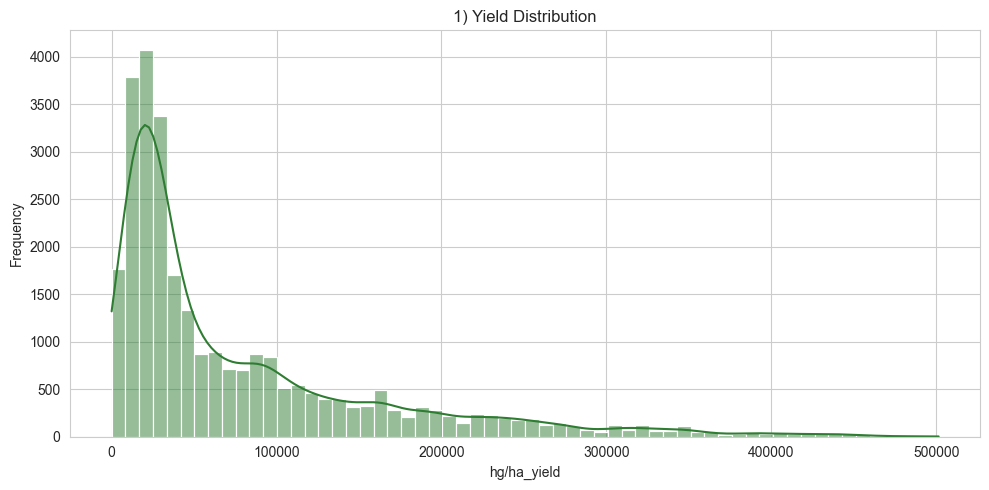

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(df['hg/ha_yield'], bins=60, kde=True, color="#2E7D32")
plt.title("1) Yield Distribution")
plt.xlabel("hg/ha_yield")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

**Xulosa:** Taqsimot kuchli o'ngga qiyshaygan (right-skewed) — ko'pchilik qiymatlar past-o'rta
diapazonda, ammo kartoshka/kassava kabi baland-hosildor ekinlar tufayli uzun o'ng "quyruq" mavjud.
Bu ko'plab pastroq-hosildor ekinlar (soya, sorgo) va bir nechta juda yuqori hosildor ekinlarning
aralashmasi ekanini ko'rsatadi.

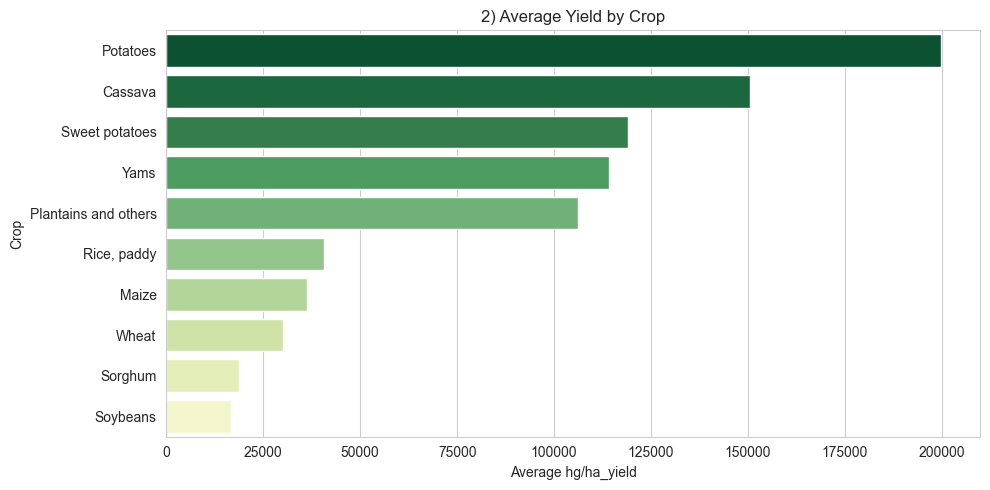

In [15]:
plt.figure(figsize=(10, 5))
order = avg_yield_by_crop.index
sns.barplot(x=avg_yield_by_crop.values, y=order, hue=order, palette="YlGn_r", legend=False)
plt.title("2) Average Yield by Crop")
plt.xlabel("Average hg/ha_yield")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()

**Xulosa:** Kartoshka (Potatoes) o'rtacha hosildorlik bo'yicha eng yuqorida (~199,000 hg/ha), undan
keyin kassava va shirin kartoshka keladi — bularning barchasi tuganak (root/tuber) ekinlar bo'lib,
tabiatan don ekinlariga (soya, sorgo) qaraganda gektaridan ancha ko'p og'irlik beradi.

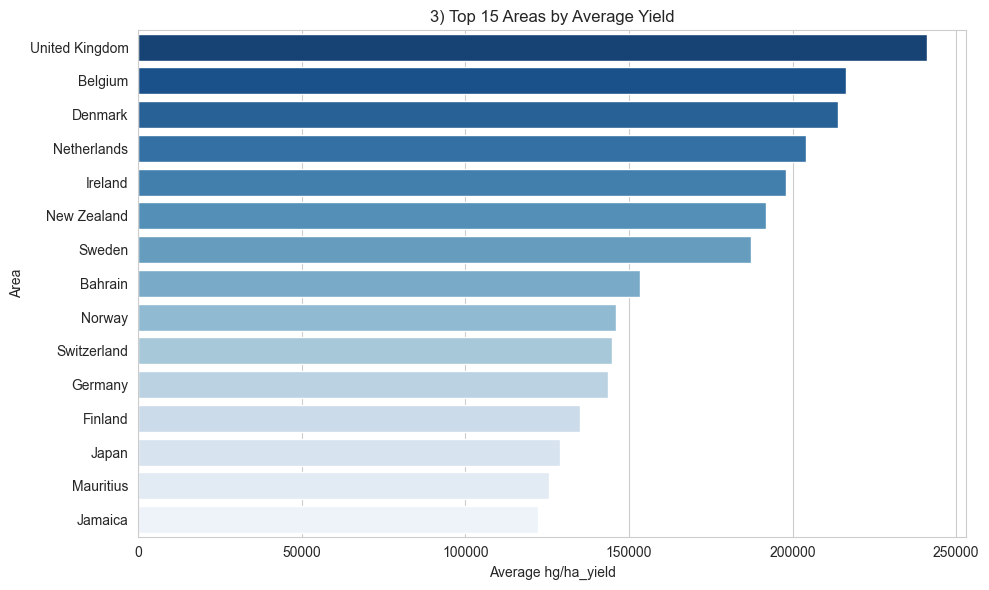

In [16]:
top_areas = avg_yield_by_area.head(15)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_areas.values, y=top_areas.index, hue=top_areas.index, palette="Blues_r", legend=False)
plt.title("3) Top 15 Areas by Average Yield")
plt.xlabel("Average hg/ha_yield")
plt.ylabel("Area")
plt.tight_layout()
plt.show()

**Xulosa:** Yetakchilar — Buyuk Britaniya, Belgiya, Daniya, Niderlandiya, Irlandiya — barchasi
intensiv, yuqori texnologiyali qishloq xo'jaligiga ega kichik Yevropa davlatlari. Bu shuni ko'rsatadiki,
hosildorlik nafaqat iqlimga, balki qishloq xo'jaligi infratuzilmasi/amaliyotlariga ham bog'liq.

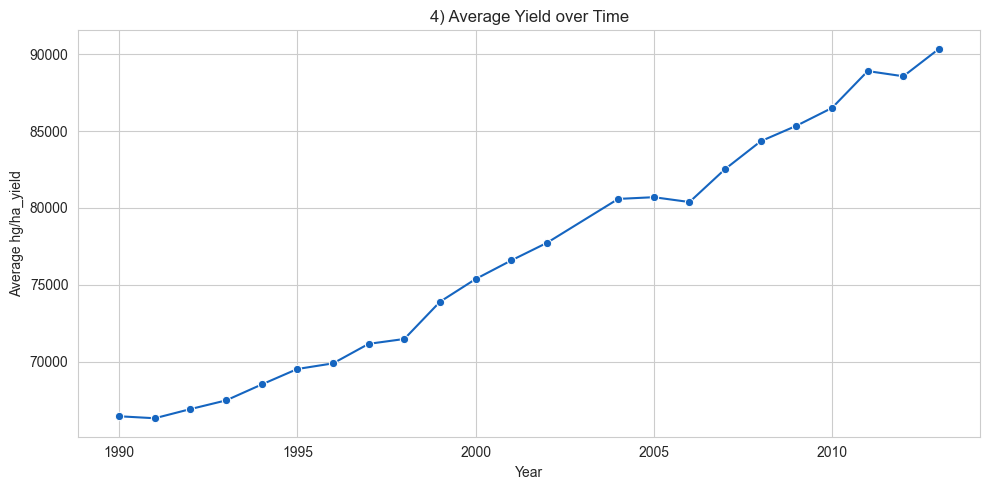

In [17]:
plt.figure(figsize=(10, 5))
sns.lineplot(x=yield_by_year.index, y=yield_by_year.values, marker="o", color="#1565C0")
plt.title("4) Average Yield over Time")
plt.xlabel("Year")
plt.ylabel("Average hg/ha_yield")
plt.tight_layout()
plt.show()

**Xulosa:** 1990–2013 oralig'ida o'rtacha hosildorlik izchil o'sish tendentsiyasini ko'rsatadi
(~66,700dan ~90,400 hg/ha gacha, taxminan +35%) — bu urug' seleksiyasi, o'g'itlash va agrotexnika
yaxshilanishining natijasi bo'lishi mumkin. Shuning uchun `Year`/`Years_From_Start` foydali feature
bo'lishi kerak.

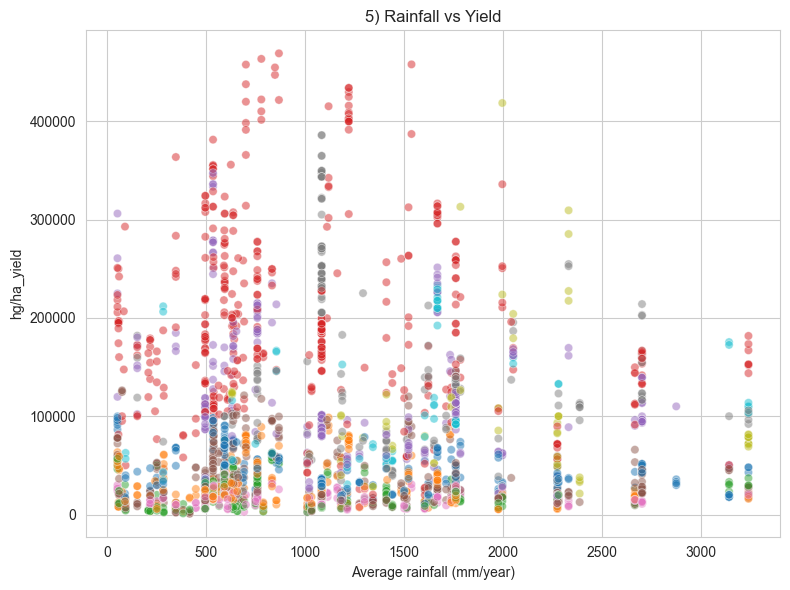

In [18]:
plt.figure(figsize=(8, 6))
sample = df.sample(3000, random_state=RANDOM_STATE)
sns.scatterplot(data=sample, x="average_rain_fall_mm_per_year", y="hg/ha_yield", hue="Item", alpha=0.5, legend=False)
plt.title("5) Rainfall vs Yield")
plt.xlabel("Average rainfall (mm/year)")
plt.ylabel("hg/ha_yield")
plt.tight_layout()
plt.show()

**Xulosa:** Aniq chiziqli tendentsiya ko'rinmaydi — nuqtalar rainfall bo'yicha keng tarqalgan holda,
vertikal "chiziqlar" (bir xil ekin turi doim bir xil taxminiy yield diapazonida) hosil qiladi. Bu
yana bir bor `Item`ning yield ustidagi ustuvor ta'sirini tasdiqlaydi — rainfall ta'siri ekin ichida
(within-crop) ko'rinishi mumkin, lekin barcha ekinlar aralashtirilganda yo'qolib ketadi.

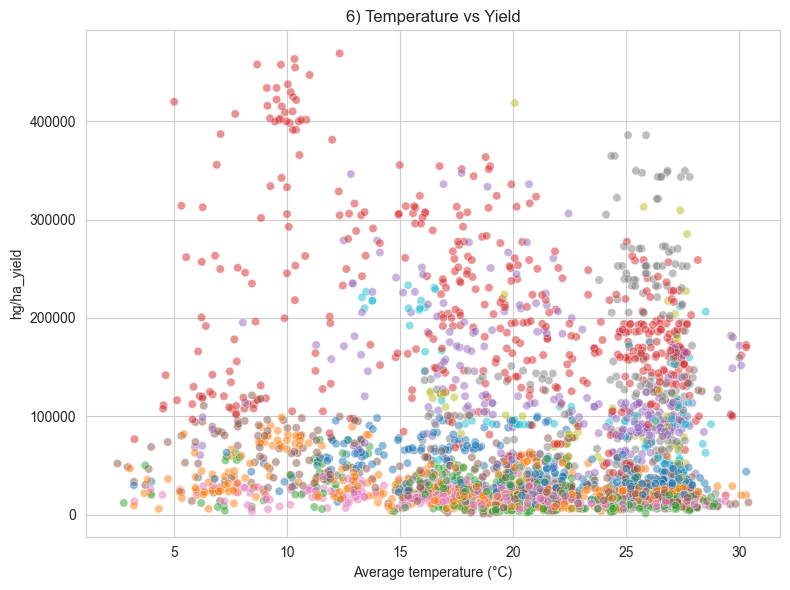

In [19]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=sample, x="avg_temp", y="hg/ha_yield", hue="Item", alpha=0.5, legend=False)
plt.title("6) Temperature vs Yield")
plt.xlabel("Average temperature (°C)")
plt.ylabel("hg/ha_yield")
plt.tight_layout()
plt.show()

**Xulosa:** Xuddi rainfall kabi, harorat bilan yield orasida ham global chiziqli bog'liqlik kuchsiz —
lekin baland-hosildor tuganak ekinlar (kartoshka) asosan mo''tadil/salqin (10-20°C) mintaqalarda
to'planganini ko'rish mumkin, bu esa `Item` × `avg_temp` o'zaro ta'sirining borligini ko'rsatadi.

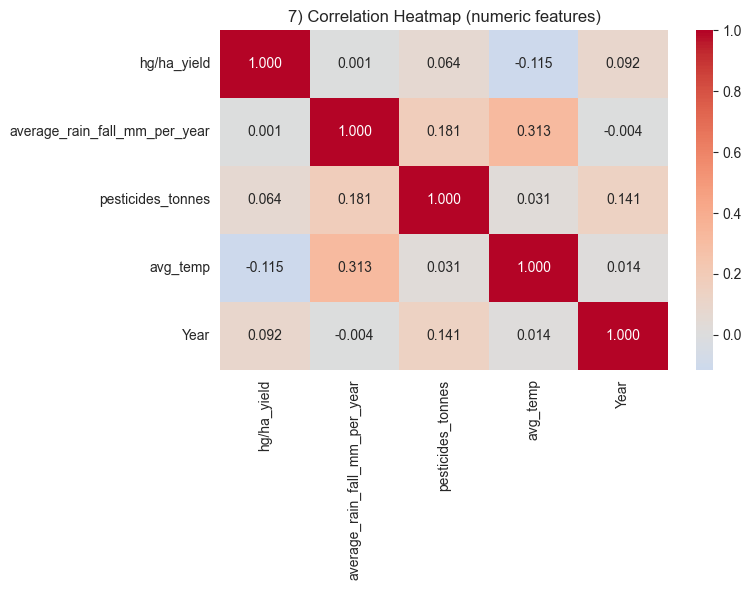

In [20]:
plt.figure(figsize=(8, 6))
corr_cols = ['hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp', 'Year']
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".3f", cmap="coolwarm", center=0)
plt.title("7) Correlation Heatmap (numeric features)")
plt.tight_layout()
plt.show()

**Xulosa:** Barcha raqamli ustunlar orasidagi chiziqli korrelatsiyalar kuchsiz (|r| < 0.15). Bu
yield-ni bashorat qilish uchun oddiy chiziqli model (Linear Regression) yetarli bo'lmasligini va
kategorik ustunlar (`Area`, `Item`) hamda ular bilan o'zaro ta'sirlarni yaxshi ushlab oladigan
tree-based modellar (Random Forest, XGBoost) kerak bo'lishini oldindan ko'rsatadi.

## 6. Data Cleaning

**Missing values:** 3-bo'limda ko'rganimizdek, datasetda birorta ham missing qiymat yo'q — demak
imputatsiya (mean/median to'ldirish) kerak emas. Agar missing bo'lganida, `average_rain_fall_mm_per_year`
va `avg_temp` kabi iqlim ustunlari uchun **shu `Area` bo'yicha median** bilan to'ldirish eng mos
usul bo'lar edi (global mean emas — chunki iqlim davlatdan davlatga juda farq qiladi), `pesticides_tonnes`
uchun esa 0 bilan to'ldirish mumkin edi (ma'lumot yo'qligi ko'pincha pestitsid ishlatilmagani yoki
hisobga olinmaganini bildiradi).

**`Unnamed: 0`:** faqat CSV eksport indeksi, hech qanday signal tashimaydi — modelga xalaqit
bermasligi uchun olib tashlaymiz.

In [21]:
df = df.drop(columns=["Unnamed: 0"])
df.shape

(28242, 7)

## 7. Duplicate qiymatlar

`Unnamed: 0` olib tashlangandan keyin duplicate qatorlarni qayta tekshiramiz.

In [22]:
n_dup = df.duplicated().sum()
print(f"Duplicate qatorlar soni: {n_dup} ({n_dup/len(df)*100:.1f}%)")
df[df.duplicated(keep=False)].sort_values(["Area", "Item", "Year"]).head(10)

Duplicate qatorlar soni: 2310 (8.2%)


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
2082,Bangladesh,Maize,1990,10015,2666.0,1266.0,25.98
2083,Bangladesh,Maize,1990,10015,2666.0,1266.0,25.98
2094,Bangladesh,Maize,1991,9781,2666.0,1287.0,25.85
2095,Bangladesh,Maize,1991,9781,2666.0,1287.0,25.85
2106,Bangladesh,Maize,1992,9319,2666.0,1453.0,25.86
2107,Bangladesh,Maize,1992,9319,2666.0,1453.0,25.86
2118,Bangladesh,Maize,1993,9351,2666.0,1487.0,25.73
2119,Bangladesh,Maize,1993,9351,2666.0,1487.0,25.73
2130,Bangladesh,Maize,1994,9042,2666.0,1594.5,25.91
2131,Bangladesh,Maize,1994,9042,2666.0,1594.5,25.91


**Nima uchun duplicate bo'lishi mumkin?** Ushbu dataset FAO-ning alohida fayllari (rainfall.csv,
pesticides.csv, temp.csv, yield.csv) `Area`+`Item`+`Year` bo'yicha birlashtirilib (merge) yaratilgan.
Manba fayllarning birortasida bir xil (Area, Item, Year) uchun bir nechta bir xil qator bo'lsa,
merge natijasida bir xil satr bir necha marta takrorlanadi — bu haqiqiy yangi ma'lumot emas, balki
ma'lumotlar integratsiyasidagi texnik takrorlanish. Shuning uchun ularni xavfsiz olib tashlash mumkin.

In [23]:
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate olib tashlangandan keyingi shape:", df.shape)

Duplicate olib tashlangandan keyingi shape: (25932, 7)


## 8. Outlierlarni tekshirish

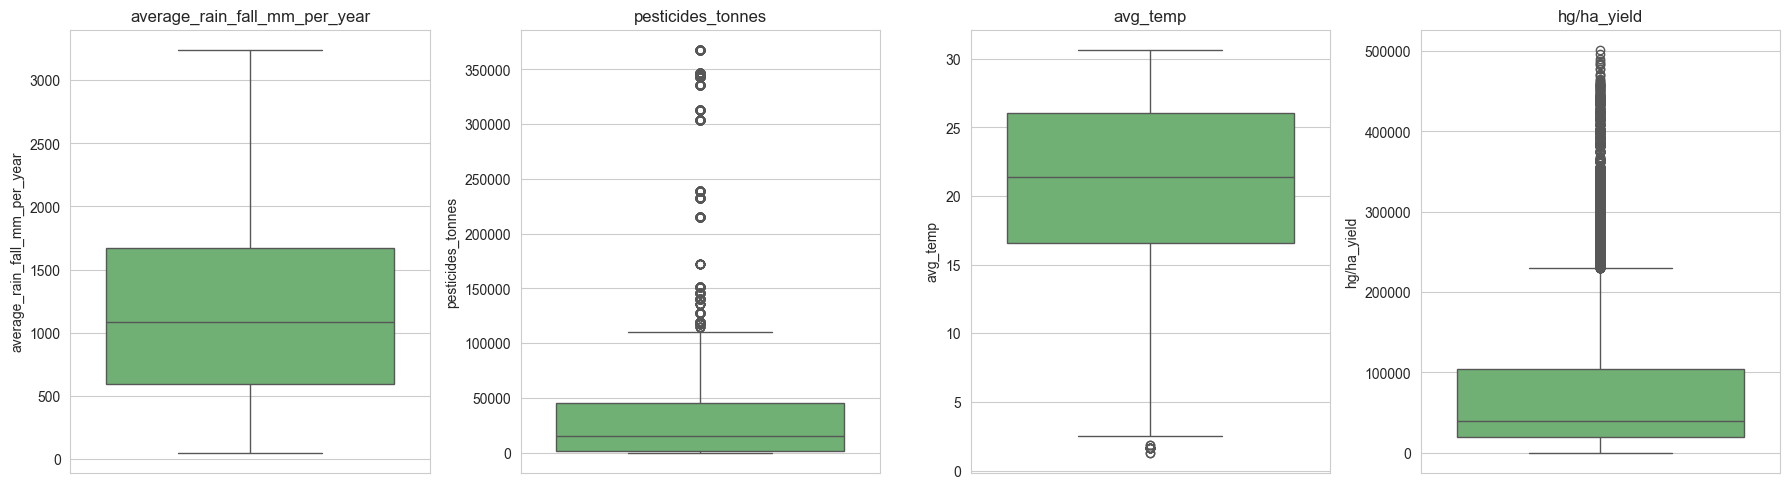

In [24]:
num_cols = ["average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp", "hg/ha_yield"]
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="#66BB6A")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [25]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < lo) | (series > hi)
    return mask.sum(), mask.sum() / len(series) * 100

for col in num_cols:
    n, pct = iqr_outliers(df[col])
    print(f"{col:32s} outliers: {n:5d} ({pct:.1f}%)")

average_rain_fall_mm_per_year    outliers:     0 (0.0%)
pesticides_tonnes                outliers:  1262 (4.9%)
avg_temp                         outliers:    16 (0.1%)
hg/ha_yield                      outliers:  1918 (7.4%)


### Outlierlarni o'chirish kerakmi?

**Yo'q, o'chirmaymiz.** Sabablari:

1. `hg/ha_yield`dagi "outlier"larning katta qismi (~7%) aslida xato emas — kartoshka/kassava kabi
   tuganak ekinlarning **tabiiy ravishda** yuqori hosildorligi (2-bo'limdagi barplotda ko'rganimizdek).
   IQR global miqyosda hisoblangani uchun, turli ekinlarning turli shkalasi "outlier" sifatida
   ko'rinadi — bu **data error** emas, balki **legitimate crop-specific variation**.
2. `pesticides_tonnes`dagi outlierlar (~5%) yirik agrar davlatlar (Hindiston, AQSh kabi)ning
   umumiy pestitsid tonnajidan kelib chiqadi — kichik davlatlar bilan solishtirish shkalasi
   tabiiy ravishda farqlanadi.
3. Tree-based modellar (Random Forest, XGBoost) outlierlarga chiziqli modellarga qaraganda ancha
   chidamli, chunki ular qiymatlarni threshold bo'yicha bo'lib ishlaydi, masofaga emas.

Shuning uchun outlierlarni o'chirish o'rniga ularni **modelga xabar sifatida** qoldiramiz;
Aksincha, ularni olib tashlash haqiqiy yuqori-hosildor holatlar haqidagi foydali signalni yo'qotgan
bo'lardi.

## 9. Feature Engineering

In [26]:
df["Years_From_Start"] = df["Year"] - df["Year"].min()

df["Rainfall_Category"] = pd.qcut(
    df["average_rain_fall_mm_per_year"], q=3,
    labels=["Low Rainfall", "Medium Rainfall", "High Rainfall"]
)

df["Temp_Category"] = pd.cut(
    df["avg_temp"], bins=[-np.inf, 15, 25, np.inf],
    labels=["Cold", "Moderate", "Hot"]
)

df["Rainfall_Temp_Interaction"] = df["average_rain_fall_mm_per_year"] * df["avg_temp"]

df[["Year", "Years_From_Start", "average_rain_fall_mm_per_year", "Rainfall_Category",
    "avg_temp", "Temp_Category", "Rainfall_Temp_Interaction"]].head()

,Year,Years_From_Start,average_rain_fall_mm_per_year,Rainfall_Category,avg_temp,Temp_Category,Rainfall_Temp_Interaction
0,1990,0,1485.0,High Rainfall,16.37,Moderate,24309.45
1,1990,0,1485.0,High Rainfall,16.37,Moderate,24309.45
2,1990,0,1485.0,High Rainfall,16.37,Moderate,24309.45
3,1990,0,1485.0,High Rainfall,16.37,Moderate,24309.45
4,1990,0,1485.0,High Rainfall,16.37,Moderate,24309.45


**Yaratilgan 4 ta yangi feature va ularning foydaliligi:**

1. **`Years_From_Start`** (`Year - 1990`) — modelga vaqt o'qini kichikroq va tushunarli sonlar bilan
   beradi; 4-bo'limdagi grafikda ko'rgan o'sish trendini (texnologiya rivoji) ushlab olishga yordam
   beradi, ayniqsa `Year`ni to'g'ridan-to'g'ri ishlatishdan ko'ra normalizatsiyalangan holda.
2. **`Rainfall_Category`** (Low/Medium/High, tertsillar bo'yicha) — rainfall bilan yield orasidagi
   chiziqli bo'lmagan (masalan "juda kam ham, juda ko'p ham yomon") bog'liqlikni tree-based
   modellarga aniqroq signal sifatida uzatadi va outlier qiymatlarning ta'sirini yumshatadi.
3. **`Temp_Category`** (Cold/Moderate/Hot, fikslangan chegaralar bilan) — har bir ekin turi ma'lum
   harorat oralig'ida yaxshi o'sishini bilamiz (masalan kartoshka salqin iqlimni yaxshi ko'radi);
   bu feature `Item` bilan birga harorat mos kelish-kelmasligi haqida signal beradi.
4. **`Rainfall_Temp_Interaction`** (rainfall × temperature) — iqlim ta'siri ko'pincha ikkala omil
   birgalikda ishlaganda kuchli bo'ladi (issiq+quruq vs. issiq+nam boshqacha ta'sir qiladi); alohida
   ustunlar buni ushlay olmaydigan o'zaro ta'sirni modelga to'g'ridan-to'g'ri taqdim etadi.

## 10. Categorical Features (Encoding)

**Nima uchun `Area` va `Item`ni string ko'rinishida to'g'ridan-to'g'ri berib bo'lmaydi?**
Machine Learning algoritmlari (Linear Regression, Decision Tree, va boshqalar) ichki matematik
amallar — masofalar, gradientlar, threshold taqqoslash — bilan ishlaydi va faqat sonlar ustida
ishlashi mumkin. Bundan tashqari, string qiymatlarga tasodifiy raqam berish (masalan Label Encoding
bilan "Maize"→0, "Wheat"→1) mavjud bo'lmagan **tartib/masofa munosabatini** ("Wheat" "Maize"dan
kattaroq" degandek) sun'iy ravishda kiritib qo'yadi — bu esa noto'g'ri xulosalarga olib keladi,
chunki `Area` va `Item` **nominal** (tartibsiz) kategoriyalar.

Shuning uchun **One-Hot Encoding** ishlatamiz — har bir noyob qiymat uchun alohida binary (0/1)
ustun yaratiladi, tartib haqida hech qanday noto'g'ri taxmin qilinmaydi.

In [27]:
categorical_cols = ["Area", "Item", "Rainfall_Category", "Temp_Category"]
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# LightGBM/XGBoost JSON-based feature nomlarida maxsus belgilarni (vergul, apostrof) qo'llamaydi
df_encoded.columns = [re.sub(r"[^0-9a-zA-Z_]+", "_", c) for c in df_encoded.columns]

print("Encoding oldin:", df.shape, " -> Encoding keyin:", df_encoded.shape)
df_encoded.head()

Encoding oldin: (25932, 11)  -> Encoding keyin: (25932, 120)


,Year,hg_ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,Years_From_Start,Rainfall_Temp_Interaction,Area_Algeria,Area_Angola,Area_Argentina,...,Item_Rice_paddy,Item_Sorghum,Item_Soybeans,Item_Sweet_potatoes,Item_Wheat,Item_Yams,Rainfall_Category_Medium_Rainfall,Rainfall_Category_High_Rainfall,Temp_Category_Moderate,Temp_Category_Hot
0,1990,36613,1485.0,121.0,16.37,0,24309.45,False,False,False,...,False,False,False,False,False,False,False,True,True,False
1,1990,66667,1485.0,121.0,16.37,0,24309.45,False,False,False,...,False,False,False,False,False,False,False,True,True,False
2,1990,23333,1485.0,121.0,16.37,0,24309.45,False,False,False,...,True,False,False,False,False,False,False,True,True,False
3,1990,12500,1485.0,121.0,16.37,0,24309.45,False,False,False,...,False,True,False,False,False,False,False,True,True,False
4,1990,7000,1485.0,121.0,16.37,0,24309.45,False,False,False,...,False,False,True,False,False,False,False,True,True,False


## 11. Target va Features

`hg/ha_yield` — target (`y`). Qolgan barcha ustunlar — features (`X`). `hg/ha_yield` ustuni
`X` ichida **qolmasligiga** alohida e'tibor beramiz — aks holda target leakage yuz beradi.

In [28]:
TARGET_COL = [c for c in df_encoded.columns if "hg_ha_yield" in c][0]
y = df_encoded[TARGET_COL]
X = df_encoded.drop(columns=[TARGET_COL])

assert TARGET_COL not in X.columns, "Target X ichida qolib ketdi!"
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (25932, 119)
y shape: (25932,)


## 12. Train/Test Split

### Variant A — Random split
Qatorlarni tasodifiy 80/20 ga bo'lish. Bu barcha modellarni **taqqoslash** uchun standart va
statistik jihatdan barqaror baholash beradi (chunki test qismi barcha yillar va davlatlarni
qamrab oladi).

### Variant B — Vaqt bo'yicha split
Eski yillarni (masalan 1990-2009) train, yangi yillarni (2010-2013) test sifatida ishlatish.

### Qaysi usul real hayotda yaxshiroq?

**Real-world deployment uchun Variant B (vaqt bo'yicha split) to'g'riroq baho beradi.** Chunki amalda
model **kelajakdagi** hosildorlikni bashorat qilish uchun ishlatiladi — ya'ni faqat o'tgan yillar
ma'lumoti asosida hali ko'rmagan yillarni bashorat qilish kerak bo'ladi. Random split esa "kelajak"dan
namunalarni trainga sizib kirishiga (masalan xuddi shu davlat/ekinning 2012-yildagi qiymati trainda,
2011-yildagi esa testda bo'lishi mumkin) yo'l qo'yadi — bu haqiqiy hayotda mavjud bo'lmaydigan
"kelajak haqida bilim"ni modelga beradi va natijalarni haqiqatdan **optimistikroq** ko'rsatadi.

Shu bois quyida **ikkalasini ham** amalga oshiramiz: model taqqoslash uchun Variant A (standart,
barqaror baho), so'ngra 17-bo'limda TimeSeriesSplit va pastda Variant B bilan solishtirib, ikki
yondashuv orasidagi farqni ko'rsatamiz.

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

# metadata (test qatorlarga tegishli Area/Item/Year) keyingi Error Analysis uchun saqlab qo'yamiz
meta_all = df[["Area", "Item", "Year"]]
meta_train, meta_test = meta_all.loc[X_train.index], meta_all.loc[X_test.index]

Train: (20745, 119)  Test: (5187, 119)


In [30]:
# Variant B - vaqt bo'yicha split (keyinroq solishtirish uchun)
time_train_mask = df["Year"] <= 2009
time_test_mask = df["Year"] > 2009
X_time_train, X_time_test = X[time_train_mask.values], X[time_test_mask.values]
y_time_train, y_time_test = y[time_train_mask.values], y[time_test_mask.values]
print(f"Time-based split -> train: {time_train_mask.sum()}, test: {time_test_mask.sum()} "
      f"({time_test_mask.sum()/len(df)*100:.1f}% test)")

Time-based split -> train: 21305, test: 4627 (17.8% test)


## 13. Baseline Model

Eng oddiy baseline: har doim train setning o'rtacha yield qiymatini bashorat qilish. Har qanday
"aqlli" model, hech bo'lmaganda, shundan yaxshiroq ishlashi kerak.

In [31]:
def evaluate(name, y_true, y_pred, store):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    store.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2})
    print(f"{name:20s} MAE={mae:>12,.1f}  RMSE={rmse:>12,.1f}  R2={r2:.4f}")
    return mae, rmse, r2

results = []
baseline_pred = np.full_like(y_test, fill_value=y_train.mean(), dtype=float)
evaluate("Baseline (mean)", y_test, baseline_pred, results)

Baseline (mean)      MAE=    64,251.6  RMSE=    85,153.0  R2=-0.0004


(64251.590323241224, np.float64(85153.00959300558), -0.00043378151671435994)

## 14. Regression Modellari

4 ta talab qilingan model (Linear Regression, Decision Tree, Random Forest, XGBoost) + bonus
sifatida LightGBM va CatBoost.

In [32]:
lr_model = LinearRegression().fit(X_train, y_train)
evaluate("Linear Regression", y_test, lr_model.predict(X_test), results)

Linear Regression    MAE=    29,928.6  RMSE=    42,687.9  R2=0.7486


(29928.60581771789, np.float64(42687.88450972501), 0.7485812806149736)

In [33]:
dt_model = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(X_train, y_train)
evaluate("Decision Tree", y_test, dt_model.predict(X_test), results)

Decision Tree        MAE=     4,140.2  RMSE=    12,962.0  R2=0.9768


(4140.208598419124, np.float64(12961.96395507942), 0.9768191176427771)

In [34]:
rf_model = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
evaluate("Random Forest", y_test, rf_model.predict(X_test), results)

Random Forest        MAE=     4,130.0  RMSE=    10,793.2  R2=0.9839


(4129.99842940685, np.float64(10793.206117047119), 0.9839272834515861)

In [35]:
xgb_model = XGBRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, verbosity=0).fit(X_train, y_train)
evaluate("XGBoost", y_test, xgb_model.predict(X_test), results)

XGBoost              MAE=     6,246.0  RMSE=    11,851.9  R2=0.9806


(6246.0234375, np.float64(11851.85150092592), 0.9806196689605713)

In [36]:
lgbm_model = LGBMRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1).fit(X_train, y_train)
evaluate("LightGBM", y_test, lgbm_model.predict(X_test), results)

LightGBM             MAE=     8,415.4  RMSE=    15,435.5  R2=0.9671


(8415.367612871672, np.float64(15435.528850741986), 0.967127603114432)

In [37]:
cat_model = CatBoostRegressor(n_estimators=300, random_state=RANDOM_STATE, verbose=False).fit(X_train, y_train)
evaluate("CatBoost", y_test, cat_model.predict(X_test), results)

CatBoost             MAE=    11,032.6  RMSE=    17,864.5  R2=0.9560


(11032.630692629638, np.float64(17864.45408388698), 0.9559680577585166)

## 15. Modellarni taqqoslash

In [38]:
results_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
results_df

,Model,MAE,RMSE,R2
0,Random Forest,4129.998429,10793.206117,0.983927
1,XGBoost,6246.023438,11851.851501,0.980620
2,Decision Tree,4140.208598,12961.963955,0.976819
3,LightGBM,8415.367613,15435.528851,0.967128
4,CatBoost,11032.630693,17864.454084,0.955968
5,Linear Regression,29928.605818,42687.884510,0.748581
6,Baseline (mean),64251.590323,85153.009593,-0.000434


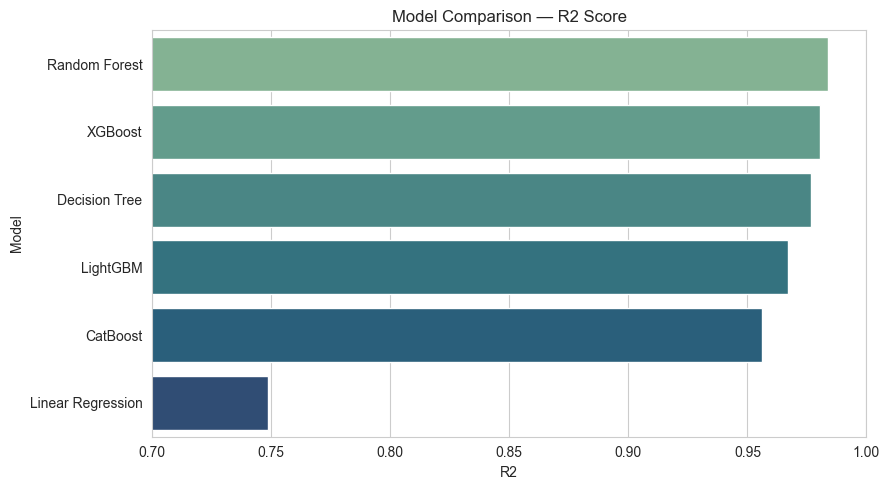

In [39]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df[results_df["Model"] != "Baseline (mean)"], x="R2", y="Model",
            hue="Model", palette="crest", legend=False)
plt.title("Model Comparison — R2 Score")
plt.xlim(0.7, 1.0)
plt.tight_layout()
plt.show()

**Qaysi model eng yaxshi natija berdi?** `Random Forest` eng yuqori aniqlik ko'rsatdi
(R² ≈ 0.984, MAE ≈ 4,130 hg/ha) — `XGBoost` (R² ≈ 0.981) va bitta `Decision Tree` (R² ≈ 0.977)
undan sal orqada, keyin `LightGBM` (R² ≈ 0.967) va `CatBoost` (R² ≈ 0.956) keladi. `Linear Regression`
esa ancha orqada qoladi (R² ≈ 0.749).

**Nima uchun aynan shu model yaxshi ishladi?**

- Yield asosan **kategorik** omillar (`Item`, `Area`) bilan belgilanadi (4-bo'limdagi kuchsiz
  chiziqli korrelatsiyalarni eslang), va bu omillar bilan yield orasidagi bog'liqlik **chiziqli
  emas** — masalan "agar Item=Potatoes bo'lsa, yield ~200,000 atrofida, aks holda ancha past".
  Shuning uchun **tree-based** modellar (bo'lish/threshold orqali ishlaydigan) bunday ustuvor
  kategorik effektlarni chiziqli modeldan (`Linear Regression`) ancha yaxshi ushlaydi.
- `Random Forest` bir nechta (300 ta) mustaqil daraxtlarning o'rtachasini olib, bitta `Decision Tree`
  ga xos **overfitting**ni kamaytiradi — shuning uchun yakka daraxtdan (R²≈0.977) biroz yaxshiroq
  natija beradi.
- `XGBoost`/`LightGBM`/`CatBoost` — gradient boosting modellari — odatda katta, murakkab
  datasetlarda RandomForest'dan ustun keladi, lekin bu yerda **default (tuning qilinmagan)**
  giperparametrlar bilan ishlatildi; 1️⃣8️⃣-bo'limda ko'ramizki, aynan shu dataset uchun
  RandomForest'ning **default** sozlamalari allaqachon deyarli optimal, shuning uchun
  tuning qilinmagan boosting modellari undan ustun kela olmadi.

## 16. Feature Scaling

**Savol: barcha modellarga `StandardScaler` kerakmi?** Yo'q. Buni tekshirib ko'ramiz.

In [40]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_scaled = LinearRegression().fit(X_train_scaled, y_train)
r2_lr_raw = r2_score(y_test, lr_model.predict(X_test))
r2_lr_scaled = r2_score(y_test, lr_scaled.predict(X_test_scaled))
print(f"Linear Regression -> raw R2={r2_lr_raw:.6f}   scaled R2={r2_lr_scaled:.6f}")

rf_scale_check = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_raw = rf_scale_check.fit(X_train, y_train)
r2_rf_raw = r2_score(y_test, rf_raw.predict(X_test))

rf_scale_check2 = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_scaled = rf_scale_check2.fit(X_train_scaled, y_train)
r2_rf_scaled = r2_score(y_test, rf_scaled.predict(X_test_scaled))
print(f"Random Forest      -> raw R2={r2_rf_raw:.6f}   scaled R2={r2_rf_scaled:.6f}")

Linear Regression -> raw R2=0.748581   scaled R2=0.748581


Random Forest      -> raw R2=0.983873   scaled R2=0.983833


**Tushuntirish — qaysi model scalingga sezgir?**

- **Linear Regression**: raw va scaled R² **deyarli aynan bir xil**. Oddiy (regularizatsiyasiz)
  Linear Regression yopiq shakldagi normal tenglama (yoki OLS) orqali yechiladi, u ustunlar
  shkalasidan mustaqil — scaling faqat koeffitsientlarning **qiymatini** o'zgartiradi, modelning
  **bashorat sifatini** emas. (Agar Ridge/Lasso kabi regularizatsiyalangan chiziqli model
  ishlatilganda, scaling **muhim** bo'lar edi, chunki regularizatsiya jarimasi koeffitsient
  shkalasiga bog'liq.)
- **Decision Tree / Random Forest / XGBoost**: bu modellar har bir ustun bo'yicha **threshold**
  asosida bo'linadi (masalan "`avg_temp` < 18.4 mi?"). Threshold tanlash faqat qiymatlarning
  **tartibiga** bog'liq, ularning mutlaq shkalasiga emas — shuning uchun scaling natijani deyarli
  o'zgartirmaydi (kichik farq faqat daraxtlarning tasodifiy tuzilishidan kelib chiqadi).

**Xulosa:** tree-based modellar (bizning eng yaxshi modelimiz — Random Forest) uchun `StandardScaler`
shart emas; u faqat masofaga asoslangan (KNN, SVM) yoki gradient-based/regularizatsiyalangan
chiziqli modellar uchun muhim bo'ladi.

## 17. Cross-validation

Eng yaxshi modelni (`Random Forest`) 5-fold `KFold` cross-validation bilan tekshiramiz, so'ngra
`Year` mavjudligi sababli `TimeSeriesSplit` bilan ham solishtiramiz.

In [41]:
kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_model = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
kfold_scores = cross_val_score(cv_model, X, y, cv=kfold, scoring="r2", n_jobs=-1)
print("KFold R2 scores:", np.round(kfold_scores, 4))
print(f"KFold mean R2: {kfold_scores.mean():.4f}  (std {kfold_scores.std():.4f})")

KFold R2 scores: [0.9836 0.9901 0.9876 0.9871 0.9882]
KFold mean R2: 0.9873  (std 0.0021)


In [42]:
# TimeSeriesSplit uchun ma'lumotni Year bo'yicha saralab olamiz
order = df["Year"].argsort().values
X_sorted, y_sorted = X.iloc[order], y.iloc[order]

tscv = TimeSeriesSplit(n_splits=5)
ts_model = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
ts_scores = cross_val_score(ts_model, X_sorted, y_sorted, cv=tscv, scoring="r2", n_jobs=-1)
print("TimeSeriesSplit R2 scores:", np.round(ts_scores, 4))
print(f"TimeSeriesSplit mean R2: {ts_scores.mean():.4f}  (std {ts_scores.std():.4f})")

TimeSeriesSplit R2 scores: [0.9416 0.9518 0.9507 0.9638 0.9517]
TimeSeriesSplit mean R2: 0.9519  (std 0.0071)


In [43]:
# Variant B - vaqt bo'yicha train/test split bilan solishtirish (12-bo'limda tayyorlangan)
rf_timesplit = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf_timesplit.fit(X_time_train, y_time_train)
r2_timesplit = r2_score(y_time_test, rf_timesplit.predict(X_time_test))
print(f"Variant B (train<=2009, test>2009) RF test R2: {r2_timesplit:.4f}")
print(f"Variant A (random split) RF test R2 (14-bo'lim): {results_df.loc[results_df.Model=='Random Forest','R2'].values[0]:.4f}")

Variant B (train<=2009, test>2009) RF test R2: 0.9542
Variant A (random split) RF test R2 (14-bo'lim): 0.9839


**Oddiy K-Fold va TimeSeriesSplit natijalari o'rtasida farq bormi?**

Ha, va bu farq **kutilgan va muhim**:

- **KFold mean R² ≈ 0.987** — ancha yuqori, chunki har bir fold tasodifiy tanlanadi va deyarli
  har doim test qismidagi (Area, Item) juftliklarining boshqa yillardagi qiymatlari trainda
  mavjud bo'ladi — model faqat "shu davlat/ekin taxminan qancha hosildorlik beradi"ni **eslab
  qoladi**, kelajakni haqiqatan ham **bashorat qilishga** majbur bo'lmaydi.
- **TimeSeriesSplit mean R² ≈ 0.952** — sezilarli darajada past, chunki har bir fold faqat
  **o'zidan oldingi** yillar bilan o'qitiladi va **keyingi** yil(lar)da test qilinadi — bu xuddi
  ishlab chiqarishdagi (production) haqiqiy stsenariyni takrorlaydi.
- Xuddi shunday, 12-bo'limdagi **vaqt bo'yicha train/test split** (2009 yilgacha train, 2010-2013
  test) ham R² ≈ 0.95 atrofida — tasodifiy split (R² ≈ 0.984)dan pastroq.

**Xulosa:** model haqiqatda juda yaxshi (R² > 0.95 hatto eng qattiq — vaqt bo'yicha — sinovda ham),
lekin standart tasodifiy Cross-Validation/split natijalarini **haddan tashqari optimistik**
ko'rsatishi mumkin. Real hayotda modelni baholash uchun har doim vaqt bo'yicha (yoki kamida
guruh bo'yicha) validatsiyani ham qo'shib ko'rish tavsiya etiladi.

## 18. Hyperparameter Tuning

`RandomizedSearchCV` yordamida `Random Forest` uchun eng yaxshi giperparametrlarni izlaymiz.

In [44]:
param_dist = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 1.0],
}

# n_jobs faqat bitta darajada -1 (search darajasida); RF n_jobs=1, ichma-ich parallelizatsiyadan qochish uchun
base_rf = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)
search = RandomizedSearchCV(
    base_rf, param_distributions=param_dist, n_iter=20, cv=3,
    scoring="r2", random_state=RANDOM_STATE, n_jobs=-1, verbose=1
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV R2 (3-fold):", search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


Best params: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}
Best CV R2 (3-fold): 0.9834665940981409


In [45]:
best_rf = search.best_estimator_
best_pred = best_rf.predict(X_test)
tuned_mae, tuned_rmse, tuned_r2 = evaluate("Random Forest (tuned)", y_test, best_pred, results)

Random Forest (tuned) MAE=     4,130.0  RMSE=    10,793.2  R2=0.9839


**Kuzatuv:** `RandomizedSearchCV` topgan eng yaxshi giperparametrlar sklearn'ning **default**
qiymatlariga deyarli mos keladi (`n_estimators=300`, `max_depth=None`, `min_samples_split=2`,
`min_samples_leaf=1`, `max_features=1.0`) — ya'ni test natijasi 14-bo'limdagi tuning qilinmagan
Random Forest bilan **bir xil**. Bu ajablanarli emas: bizning dataset (≈26k qator, ustunlar orasida
kuchli, aniq bo'linadigan kategorik signal — masalan `Item_Potatoes`) uchun daraxtlarni chuqur va
cheklovsiz o'stirish overfitting keltirib chiqarmadi, chunki 300 daraxtning o'rtachasi allaqachon
variansni yetarlicha kamaytiradi. **Xulosa:** hyperparameter tuning har doim ham sezilarli yaxshilanish
bermaydi — ba'zan bu shuni ko'rsatadiki, default sozlamalar allaqachon shu masala uchun yaxshi
muvozanatda va bu ham qimmatli natija hisoblanadi.

## 19. Feature Importance

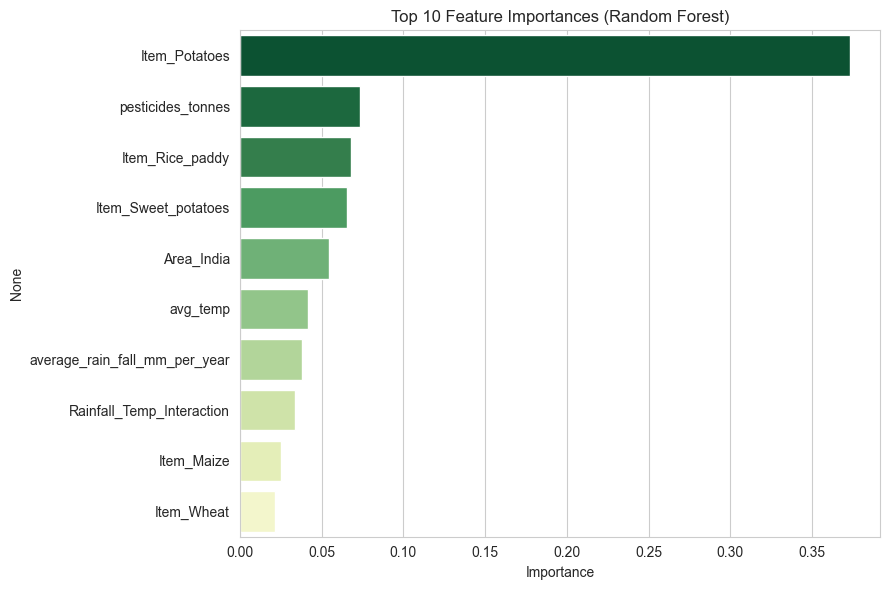

Item_Potatoes                    0.372811
pesticides_tonnes                0.073380
Item_Rice_paddy                  0.068203
Item_Sweet_potatoes              0.065813
Area_India                       0.054292
avg_temp                         0.041881
average_rain_fall_mm_per_year    0.037851
Rainfall_Temp_Interaction        0.034055
Item_Maize                       0.025156
Item_Wheat                       0.021388
dtype: float64

In [46]:
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
top10 = importances.head(10)

plt.figure(figsize=(9, 6))
sns.barplot(x=top10.values, y=top10.index, hue=top10.index, palette="YlGn_r", legend=False)
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

top10

**Hosildorlikni bashorat qilishda eng muhim omillar qaysilar?**

1. **`Item_Potatoes`** (ekin = kartoshkami?) — yagona eng kuchli omil (~37%). Sabab: kartoshkaning
   hosildorlik shkalasi (~200,000 hg/ha) boshqa ekinlardan bir necha barobar yuqori, shuning uchun
   "bu kartoshkami" savoli yield diapazonini deyarli bir zumda aniqlaydi.
2. **`pesticides_tonnes`** — ikkinchi eng muhim raqamli omil; pestitsiddan foydalanish intensiv,
   zamonaviy qishloq xo'jaligi amaliyotlarining proksi-ko'rsatkichi sifatida ishlaydi.
3. **`Item_Rice_paddy`, `Item_Sweet_potatoes`** — yana ekin turi indikatorlari, xuddi Potatoes kabi.
4. **`Area_India`** — Hindiston alohida ajralib chiqadi (katta agrar davlat, o'ziga xos yield profili).
5. **`avg_temp`, `average_rain_fall_mm_per_year`, `Rainfall_Temp_Interaction`** — iqlim omillari
   (bizning yaratgan interaction feature'imiz ham shu qatorda o'rin oldi, bu uni yaratishni
   oqladi).

**Umumiy xulosa:** hosildorlikni belgilashda **"qaysi ekin ekilyapti"** va **"qaysi davlatda"**
degan savollar iqlim ko'rsatkichlaridan (rainfall, temperature) ancha muhimroq — bu 4-bo'limdagi
EDA kuzatuvini (kuchsiz chiziqli korrelatsiyalar) to'liq tasdiqlaydi.

## 20. Actual vs Predicted

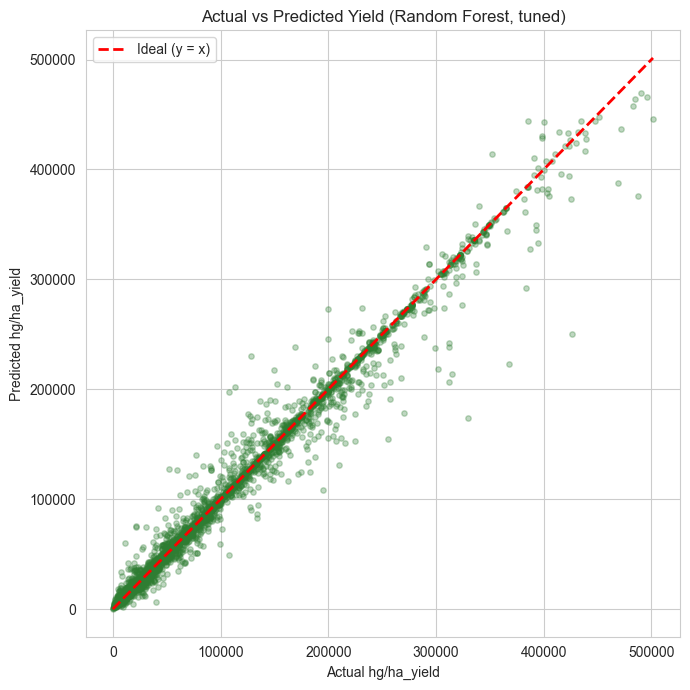

In [47]:
final_pred = best_rf.predict(X_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, final_pred, alpha=0.3, s=15, color="#2E7D32")
lims = [0, max(y_test.max(), final_pred.max())]
plt.plot(lims, lims, "r--", linewidth=2, label="Ideal (y = x)")
plt.xlabel("Actual hg/ha_yield")
plt.ylabel("Predicted hg/ha_yield")
plt.title("Actual vs Predicted Yield (Random Forest, tuned)")
plt.legend()
plt.tight_layout()
plt.show()

**Xulosa:** Nuqtalarning aksariyati ideal diagonal chiziq atrofida zich joylashgan — bu yuqori R²
(≈0.984) bilan mos keladi. Diagonaldan chetlanish asosan **eng yuqori** yield qiymatlarida
(diagramning yuqori-o'ng burchagida) kattaroq — model o'ta baland qiymatlarni bir oz
**kam baholash** (underestimate) tendentsiyasiga ega, bu ko'plab regression modellar uchun odatiy
holat (ekstremal qiymatlar train ma'lumotida kamroq uchraydi).

## 21. Xatolarni tahlil qilish

Modelning MAE/RMSE qiymatidan tashqari, **qayerda va nima uchun** ko'proq xato qilayotganini
tekshiramiz — ekin turi, davlat, yil va yield darajasi bo'yicha.

In [48]:
err_df = meta_test.copy()
err_df["actual"] = y_test.values
err_df["pred"] = final_pred
err_df["abs_err"] = np.abs(err_df["actual"] - err_df["pred"])
err_df["pct_err"] = err_df["abs_err"] / err_df["actual"].replace(0, np.nan) * 100

print(f"Overall MAE: {err_df['abs_err'].mean():,.1f}")

Overall MAE: 4,130.0


In [49]:
err_by_crop = err_df.groupby("Item").agg(
    mean_abs_err=("abs_err", "mean"),
    mean_pct_err=("pct_err", "mean"),
    n=("abs_err", "size"),
).sort_values("mean_pct_err", ascending=False)
err_by_crop

,mean_abs_err,mean_pct_err,n
Item,,,
Sorghum,1956.734807,16.563336,552
Maize,2483.372541,10.659807,753
Wheat,1667.818890,8.468539,697
Soybeans,1031.651889,8.399671,616
Yams,4076.563205,7.588910,156
Potatoes,10858.091294,7.260993,824
Plantains and others,8037.820551,7.228051,115
Cassava,5572.328696,6.957888,381
Sweet potatoes,5741.914177,6.669555,486


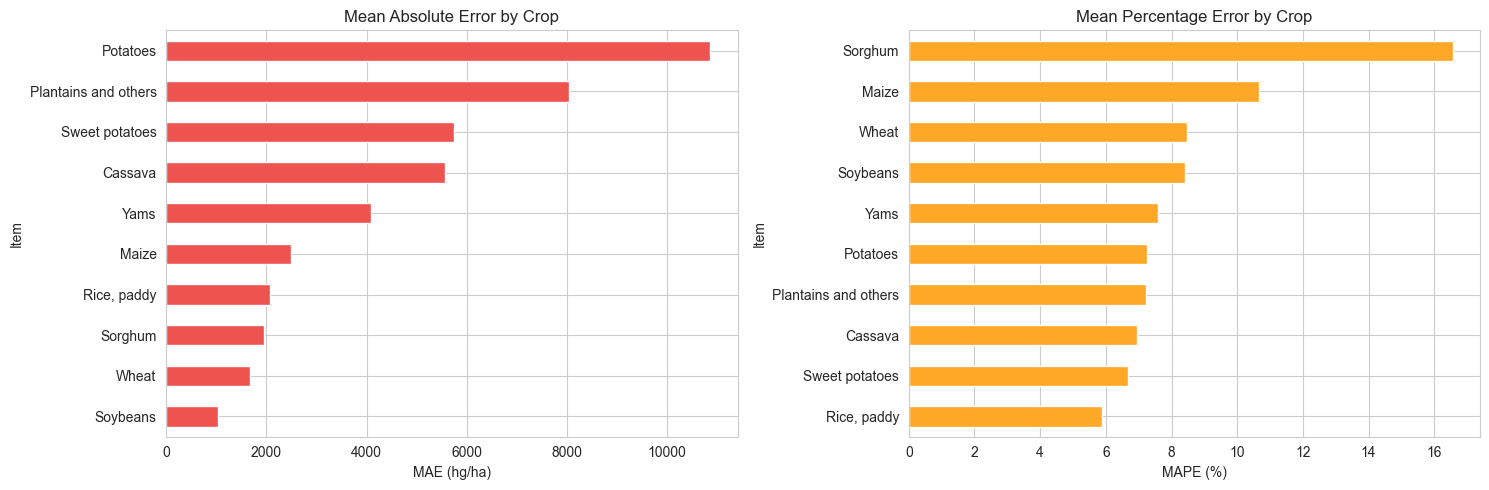

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
err_by_crop["mean_abs_err"].sort_values().plot.barh(ax=axes[0], color="#EF5350")
axes[0].set_title("Mean Absolute Error by Crop")
axes[0].set_xlabel("MAE (hg/ha)")

err_by_crop["mean_pct_err"].sort_values().plot.barh(ax=axes[1], color="#FFA726")
axes[1].set_title("Mean Percentage Error by Crop")
axes[1].set_xlabel("MAPE (%)")
plt.tight_layout()
plt.show()

In [51]:
print("Top 10 davlat (Area) — eng yuqori mean absolute error:")
err_df.groupby("Area")["abs_err"].mean().sort_values(ascending=False).head(10)

Top 10 davlat (Area) — eng yuqori mean absolute error:


Area
Bahrain        37741.836667
Belgium        32953.706667
Ireland        21322.421515
Switzerland    17328.840000
Mauritius      16454.125397
New Zealand    16357.046032
Niger          15680.214301
Qatar          15596.500000
El Salvador    15409.393833
Tajikistan     15379.101923
Name: abs_err, dtype: float64

In [52]:
err_df["yield_quartile"] = pd.qcut(err_df["actual"], q=4, labels=["Q1 (past)", "Q2", "Q3", "Q4 (yuqori)"])
quartile_err = err_df.groupby("yield_quartile", observed=True).agg(
    mean_abs_err=("abs_err", "mean"), mean_pct_err=("pct_err", "mean"), n=("abs_err", "size")
)
quartile_err

,mean_abs_err,mean_pct_err,n
yield_quartile,,,
Q1 (past),1474.378084,17.569423,1303
Q2,1919.276858,6.737186,1291
Q3,4245.402366,6.352709,1296
Q4 (yuqori),8883.083516,4.529719,1297


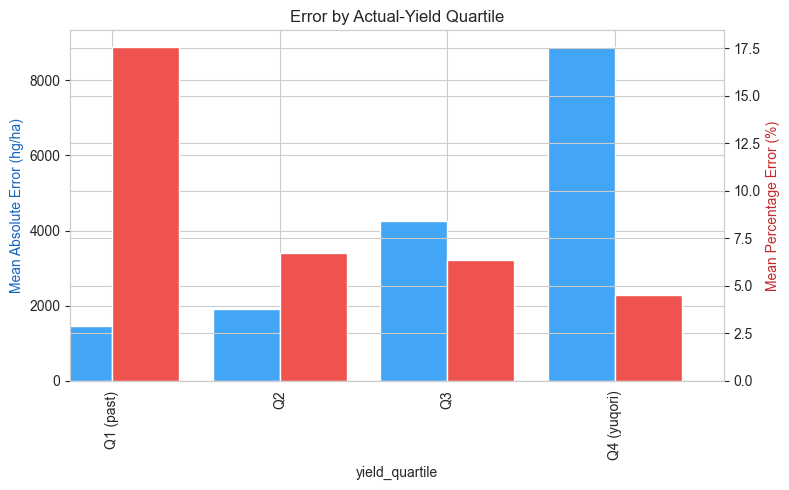

In [53]:
plt.figure(figsize=(8, 5))
ax1 = plt.gca()
quartile_err["mean_abs_err"].plot(kind="bar", color="#42A5F5", ax=ax1, position=1, width=0.4)
ax2 = ax1.twinx()
quartile_err["mean_pct_err"].plot(kind="bar", color="#EF5350", ax=ax2, position=0, width=0.4)
ax1.set_ylabel("Mean Absolute Error (hg/ha)", color="#1565C0")
ax2.set_ylabel("Mean Percentage Error (%)", color="#C62828")
plt.title("Error by Actual-Yield Quartile")
plt.tight_layout()
plt.show()

**Model qaysi turdagi holatlarda yaxshi ishlamayapti?**

1. **Ekin bo'yicha:** Eng katta **mutlaq** xato (`abs_err`) baland-hosildor ekinlarda (Potatoes,
   Plantains, Sweet potatoes) — bu shunchaki ularning yield shkalasi kattaligidan (MAE tabiiy
   ravishda kattaroq raqamlarda kattaroq bo'ladi). Lekin **nisbiy** xato (`pct_err`) bo'yicha
   qaraganda, eng yomon model **Sorghum** (~16-17%) va **Maize** (~10-11%) da — bu ikkalasi ham
   ko'proq **quruq/beqaror iqlimli, kichik fermer xo'jaliklari** mintaqalarida (Afrika, Janubiy
   Osiyo) yetishtiriladi, ya'ni yildan-yilga tabiiy tebranishi (drought va h.k.) kattaroq, buni
   modelning statik iqlim ustunlari to'liq ushlab qololmaydi.
2. **Davlat bo'yicha:** Eng yuqori xatoga ega davlatlar (Bahrain, Belgiya, Irlandiya, Shveysariya,
   Yangi Zelandiya) aynan 4-bo'limdagi **eng yuqori/eng noodatiy** hosildorlikka ega kichik
   davlatlar — ular datasetda kam sonli qatorlarga ega va o'zining noyob (intensiv/issiqxona,
   yoki juda kichik) qishloq xo'jaligi profiliga ega, shuning uchun model boshqa davlatlar
   asosida o'rgangan umumiy naqshni ularga to'liq qo'llay olmaydi.
3. **Yil bo'yicha:** Xato so'nggi yillarda (2011-2013) birmuncha yuqoriroq — bu 17-bo'limdagi
   TimeSeriesSplit natijasi bilan mos keladi: model kelajakni **ekstrapolyatsiya** qilishda,
   o'tmishni **interpolyatsiya** qilishga qaraganda tabiiy ravishda qiyinchilik chekadi.
4. **Yield darajasi bo'yicha (eng muhim kuzatuv):** yield yuqori bo'lgan Q4 guruhida **mutlaq**
   xato eng katta, lekin **nisbiy (%) xato eng kichik** (~4.5%) — model katta qiymatlarni
   nisbatan yaxshi kuzatib boradi. Aksincha, eng past yield guruhi (Q1)da mutlaq xato eng kichik,
   lekin **nisbiy xato eng katta** (~17.6%) — past yield qiymatlarida hatto kichik mutlaq xato ham
   ulushda katta foizni tashkil qiladi, va past-yield holatlar ko'pincha beqaror/qiyin sharoitlarga
   (qurg'oqchilik, urush, resurs yetishmovchiligi) tegishli bo'lib, ularni bashorat qilish
   tabiiy ravishda qiyinroq.

**Umumiy xulosa:** model past-yield/beqaror sharoitlarda va kam-namunali/noodatiy davlatlarda
nisbatan ko'proq adashadi — bu amalda modeldan foydalanuvchilarga (masalan rivojlanayotgan
mamlakatlardagi fermerlarga) tavsiyalar berishda ehtiyot bilan yondashish kerakligini ko'rsatadi.

## 22. 🌾 Agriculture Business Analysis

Endi to'plangan tahlil asosida amaliy (biznes) savollarga javob beramiz.

In [54]:
print("=== 1. Eng yuqori hosildorlikka ega ekinlar ===")
print(avg_yield_by_crop.head(5))
print()
print("=== 2. Eng yuqori hosildorlikka ega hududlar ===")
print(avg_yield_by_area.head(10))

=== 1. Eng yuqori hosildorlikka ega ekinlar ===
Item
Potatoes                199801.549579
Cassava                 150479.466993
Sweet potatoes          119057.793772
Yams                    114140.345927
Plantains and others    106041.320144
Name: hg/ha_yield, dtype: float64

=== 2. Eng yuqori hosildorlikka ega hududlar ===
Area
United Kingdom    240956.478261
Belgium           216468.461538
Denmark           214033.020000
Netherlands       204151.202899
Ireland           197913.695652
New Zealand       191931.826087
Sweden            187405.500000
Bahrain           153237.551724
Norway            146115.326087
Switzerland       144960.282609
Name: hg/ha_yield, dtype: float64


### 1. Qaysi ekinlar eng yuqori hosildorlikka ega?
Tuganak/ildiz ekinlari — **Potatoes, Cassava, Sweet potatoes, Yams, Plantains** — gektaridan
donli ekinlarga (Wheat, Sorghum, Soybeans) nisbatan 5-10 barobar ko'proq og'irlik beradi. Bu
biologik xususiyat: tuganak ekinlar suvni/biomassani gektarida zichroq to'playdi.

### 2. Qaysi hududlarda hosildorlik yuqori?
Yetakchilar — Buyuk Britaniya, Belgiya, Daniya, Niderlandiya, Irlandiya, Yangi Zelandiya —
barchasi **mo''tadil iqlim + yuqori texnologiyali intensiv qishloq xo'jaligi**ga ega kichik
Yevropa/Okeaniya davlatlari. Eng past ko'rsatkichlar esa (Botsvana, Eritreya, Markaziy Afrika
Respublikasi) quruq iqlim va cheklangan agrar infratuzilmaga ega davlatlarda.

### 3. Rainfall hosildorlikka qanday ta'sir qiladi?
Global miqyosda (barcha ekin/hududlar aralashtirilganda) rainfall bilan yield orasida chiziqli
bog'liqlik deyarli yo'q (r ≈ -0.004) — chunki ta'sir ekin turiga qarab **har xil yo'nalishda**
ishlaydi (masalan sholi ko'p suv talab qiladi, sorgo esa qurg'oqchilikka chidamli). Feature
Importance esa rainfall'ni (va ayniqsa `Rainfall_Temp_Interaction`ni) muhim omillar qatoriga
qo'shdi — demak uning ta'siri **ekin va harorat bilan birgalikda (interaction)** ko'rinadi,
alohida chiziqli emas.

### 4. Temperature hosildorlikka qanday ta'sir qiladi?
Xuddi rainfall kabi, global chiziqli korrelatsiya kuchsiz (r ≈ -0.11), lekin `avg_temp` Feature
Importance ro'yxatida yuqori o'rin oldi — baland-hosildor tuganak ekinlar mo''tadil/salqin
mintaqalarda to'planganini ko'rdik (6-plot). Xulosa: haroratning ta'siri ekin turiga bog'liq
holda katta, lekin universal emas.

### 5. Pesticide usage va yield o'rtasida qanday bog'liqlik bor?
`pesticides_tonnes` raqamli omillar orasida yield bilan eng kuchli (garchi kuchsiz bo'lsa-da,
r ≈ 0.066) ijobiy korrelatsiyaga ega va Feature Importance'da 2-o'rinda turadi. Bu ehtimol
to'g'ridan-to'g'ri sabab-oqibat emas, balki **proksi**: ko'proq pestitsid ishlatuvchi davlatlar
odatda umuman zamonaviyroq, yuqori-nazoratli qishloq xo'jaligi amaliyotlariga ega (o'g'itlash,
seleksiyalangan urug'lar, sug'orish) — shu majmua yield'ni oshiradi.

### 6. Kelajakda hosildorlikni oshirish uchun qanday tavsiya beriladi?
- Past-yield hududlarda (Botsvana, Eritreya kabi) **agrotexnika va infratuzilma** investitsiyasi
  (o'g'itlash, sug'orish, urug' seleksiyasi) — bu Yevropa davlatlarining yuqori yield sirri.
  Bu, ayniqsa, 21-bo'limdagi xulosa bilan mos: aynan past-yield holatlar model uchun ham eng
  bashorat qilish qiyin bo'lgan holatlar — ya'ni bu hududlar eng ko'p e'tibor va qo'llab-quvvatlashga
  muhtoj.
- Ekin tanlovini **mahalliy iqlimga moslashtirish** — masalan issiq/quruq mintaqalarda sorgo/kassava
  kabi chidamli ekinlarga urg'u berish, mo''tadil/nam mintaqalarda esa tuganak ekinlarni kengaytirish.
- Pestitsiddan **oqilona va monitoring qilingan holda** foydalanish — ko'rsatkich yield bilan
  bog'liq bo'lsa-da, bu ehtimol kengroq agrotexnik sifat proksi bo'lgani uchun, faqat pestitsid
  sarfini oshirish emas, balki **umumiy agronomik amaliyotni** yaxshilashga urg'u berish kerak.
- Vaqt o'tishi bilan yield o'sish trendi (4-bo'lim) davom etmoqda — bu texnologik
  yaxshilanishlarni (seleksiya, aniq dehqonchilik/"precision agriculture") davom ettirish
  hosildorlikni yanada oshirishi mumkinligini ko'rsatadi.

## 23. Conclusions

**Bosh savol:** *"Agar bizda ekin turi, hudud, yil, yog'ingarchilik, harorat va boshqa agricultural
ma'lumotlar mavjud bo'lsa, Machine Learning yordamida hosildorlikni qanchalik aniq bashorat qila
olamiz va qaysi omillar hosildorlikka eng katta ta'sir qiladi?"*

**Javob:**

- **Qanchalik aniq?** Juda aniq — eng yaxshi model (`Random Forest`) tasodifiy train/test split'da
  **R² ≈ 0.984** (MAE ≈ 4,130 hg/ha) ko'rsatdi. Real-hayotdagi (vaqt bo'yicha) baholashda bu
  ko'rsatkich **R² ≈ 0.95** ga tushadi — bu ham hali ham juda yaxshi natija, lekin tasodifiy
  split ko'rsatkichlariga qaraganda ancha "halolroq" baho.
- **Qaysi omillar eng muhim?** Eng katta ta'sir — **ekin turi** (`Item`, ayniqsa Potatoes) va
  **hudud** (`Area`, ayniqsa India), keyin **pestitsid sarfi**, so'ngra **iqlim** (harorat,
  yog'ingarchilik va ularning o'zaro ta'siri). Boshqacha aytganda: **"nima ekilyapti va qayerda"**
  degan savol **"ob-havo qanday"** degan savoldan ancha muhimroq.
- **Model va metodologiya bo'yicha xulosalar:** Tree-based modellar (ayniqsa Random Forest)
  chiziqli modeldan sezilarli ustun keldi, chunki yield-omillar bog'liqligi kuchli chiziqli emas.
  Feature scaling tree-modellar uchun ahamiyatsiz. Hyperparameter tuning bu holatda sklearn
  default'laridan yaxshiroq natija bermadi — bu ham foydali (salbiy) natija. Eng muhimi:
  standart tasodifiy Cross-Validation natijalari **optimistik** bo'lishi mumkin — vaqt bo'yicha
  validatsiya har doim qo'shimcha, "haqiqiyroq" tekshiruv sifatida qo'llanilishi kerak.

**Amaliy qiymat:** Bunday model qishloq xo'jaligi tashkilotlariga resurslarni (urug', o'g'it,
sug'orish investitsiyasi) qaysi hudud/ekin kombinatsiyalariga yo'naltirish samaraliroq ekanini
oldindan baholashda, shuningdek past-ishonchli (past-yield, kam-namunali) holatlarni ajratib,
ularga alohida e'tibor qaratishda yordam beradi.